# CIE-2 Activity 1: Multiple Linear Regression — House Price Prediction

**Student roll number:** AD3125 
**Subject:** Regression and Classification Algorithms (RCA), T.Y. B.Tech AI & DS, Zeal College of Engineering and Research 
**Unit:** Unit I — Regression Foundations and Linear Regression

**Dataset source:** Yasser H., *Housing Prices Dataset*, Kaggle. https://www.kaggle.com/datasets/yasserh/housing-prices-dataset/data 
**File:** `Housing.csv` — 545 rows, 13 columns. Currency is not stated in the source, so prices are treated as plain units.

---

## Professional framing (Thinking cycle)

| Stage | My answer |
|---|---|
| **Frame the problem** | A real-estate analyst wants to explain and estimate house prices from property features. The estimate is a guide for pricing discussions, not a valuation. |
| **Input (X) and target (y)** | Input: area, bedrooms, bathrooms, stories, parking, and six yes/no features plus furnishing status. Target: `price`. |
| **Definition of "good"** | Test-set R² well above a mean-only benchmark, and an MAE small enough to be useful in a pricing conversation. |
| **Data understanding** | Each row is one house listing. Possible issues are missing values, duplicates, and outliers. |
| **Success metric** | Test-set MAE (average error in price units) plus R², which compares the model with the mean baseline. |

## 1. Setup and reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, statsmodels
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| statsmodels", statsmodels.__version__)

pandas 3.0.6 | numpy 2.5.4 | sklearn 1.9.1 | statsmodels 0.15.0


## 2. Load and inspect the data

In [2]:
df = pd.read_csv("Housing.csv")
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe().T)

Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0


## 3. Data quality checks and cleaning

**Decision log:** I checked for missing values and duplicates. I kept every row because the data is complete and the prices and areas are plausible (the largest area is 16,200 sq ft and the largest price is 13.3 million). I did not remove any outliers, since removing them would hide real high-end houses. I converted yes/no columns to 1/0 and one-hot encoded `furnishingstatus`, dropping one category as the reference.

In [3]:
print("Missing values per column:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Binary yes/no columns -> 1/0
binary_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
for c in binary_cols:
    df[c] = (df[c] == "yes").astype(int)

# One-hot encode furnishing status; 'furnished' is the reference category (dropped)
df = pd.concat([
    df.drop(columns="furnishingstatus"),
    pd.get_dummies(df["furnishingstatus"], prefix="furn", drop_first=True, dtype=int)
], axis=1)

print("Model-ready shape:", df.shape)
print("Columns:", df.columns.tolist())

Missing values per column: 0
Duplicate rows: 0
Model-ready shape: (545, 14)
Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furn_semi-furnished', 'furn_unfurnished']


## 4. Input (X) and target (y)

Identifiers are not an issue here because the dataset has no ID column. All 12 input features are kept, because each one is a plausible driver of price and none is redundant by definition. Whether they are redundant in practice is checked later with VIF.

In [4]:
X = df.drop(columns="price")
y = df["price"]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Input features:", X.columns.tolist())

X shape: (545, 13) | y shape: (545,)
Input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furn_semi-furnished', 'furn_unfurnished']


## 5. Exploratory data analysis

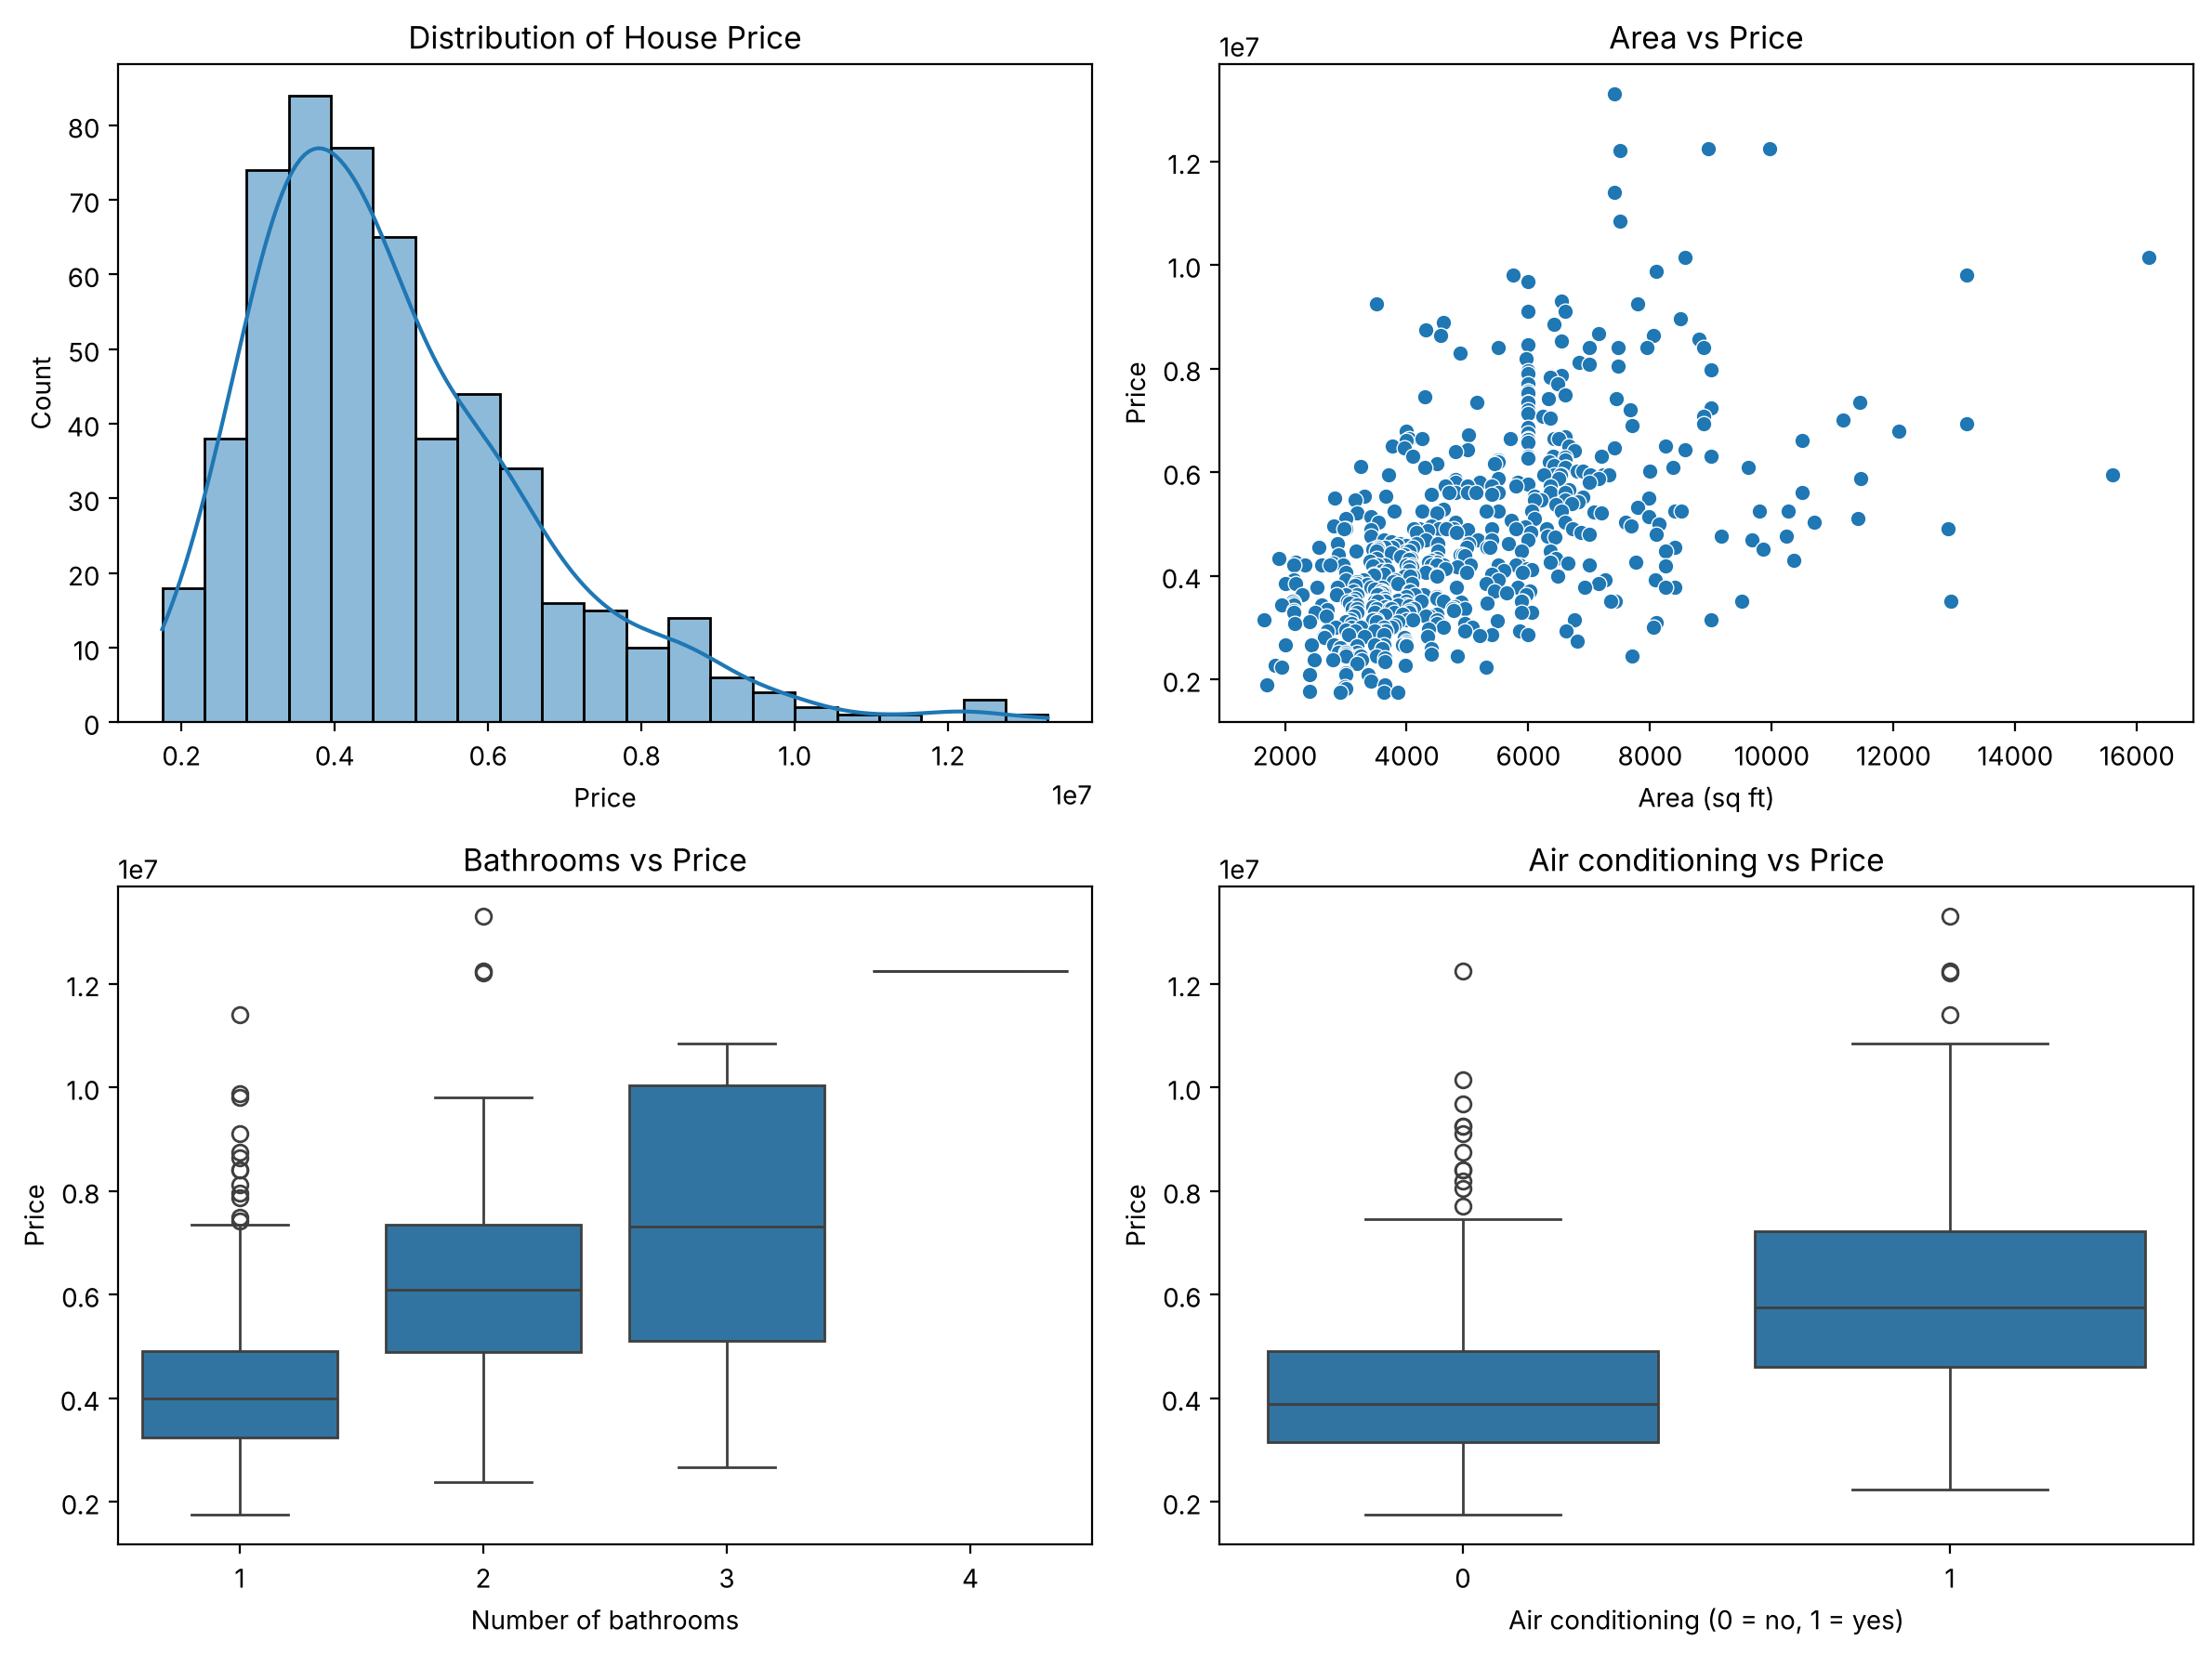

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(y, kde=True, ax=axes[0, 0])
axes[0, 0].set(title="Distribution of House Price", xlabel="Price", ylabel="Count")

sns.scatterplot(x=df["area"], y=y, ax=axes[0, 1])
axes[0, 1].set(title="Area vs Price", xlabel="Area (sq ft)", ylabel="Price")

sns.boxplot(x=df["bathrooms"], y=y, ax=axes[1, 0])
axes[1, 0].set(title="Bathrooms vs Price", xlabel="Number of bathrooms", ylabel="Price")

sns.boxplot(x=df["airconditioning"], y=y, ax=axes[1, 1])
axes[1, 1].set(title="Air conditioning vs Price", xlabel="Air conditioning (0 = no, 1 = yes)", ylabel="Price")
plt.tight_layout(); plt.show()

**Observation:** Prices are right-skewed: most houses sit between about 3.4 and 5.7 million, with a long tail up to 13.3 million. Area rises with price but spreads out at higher values. Houses with more bathrooms and with air conditioning have clearly higher median prices.

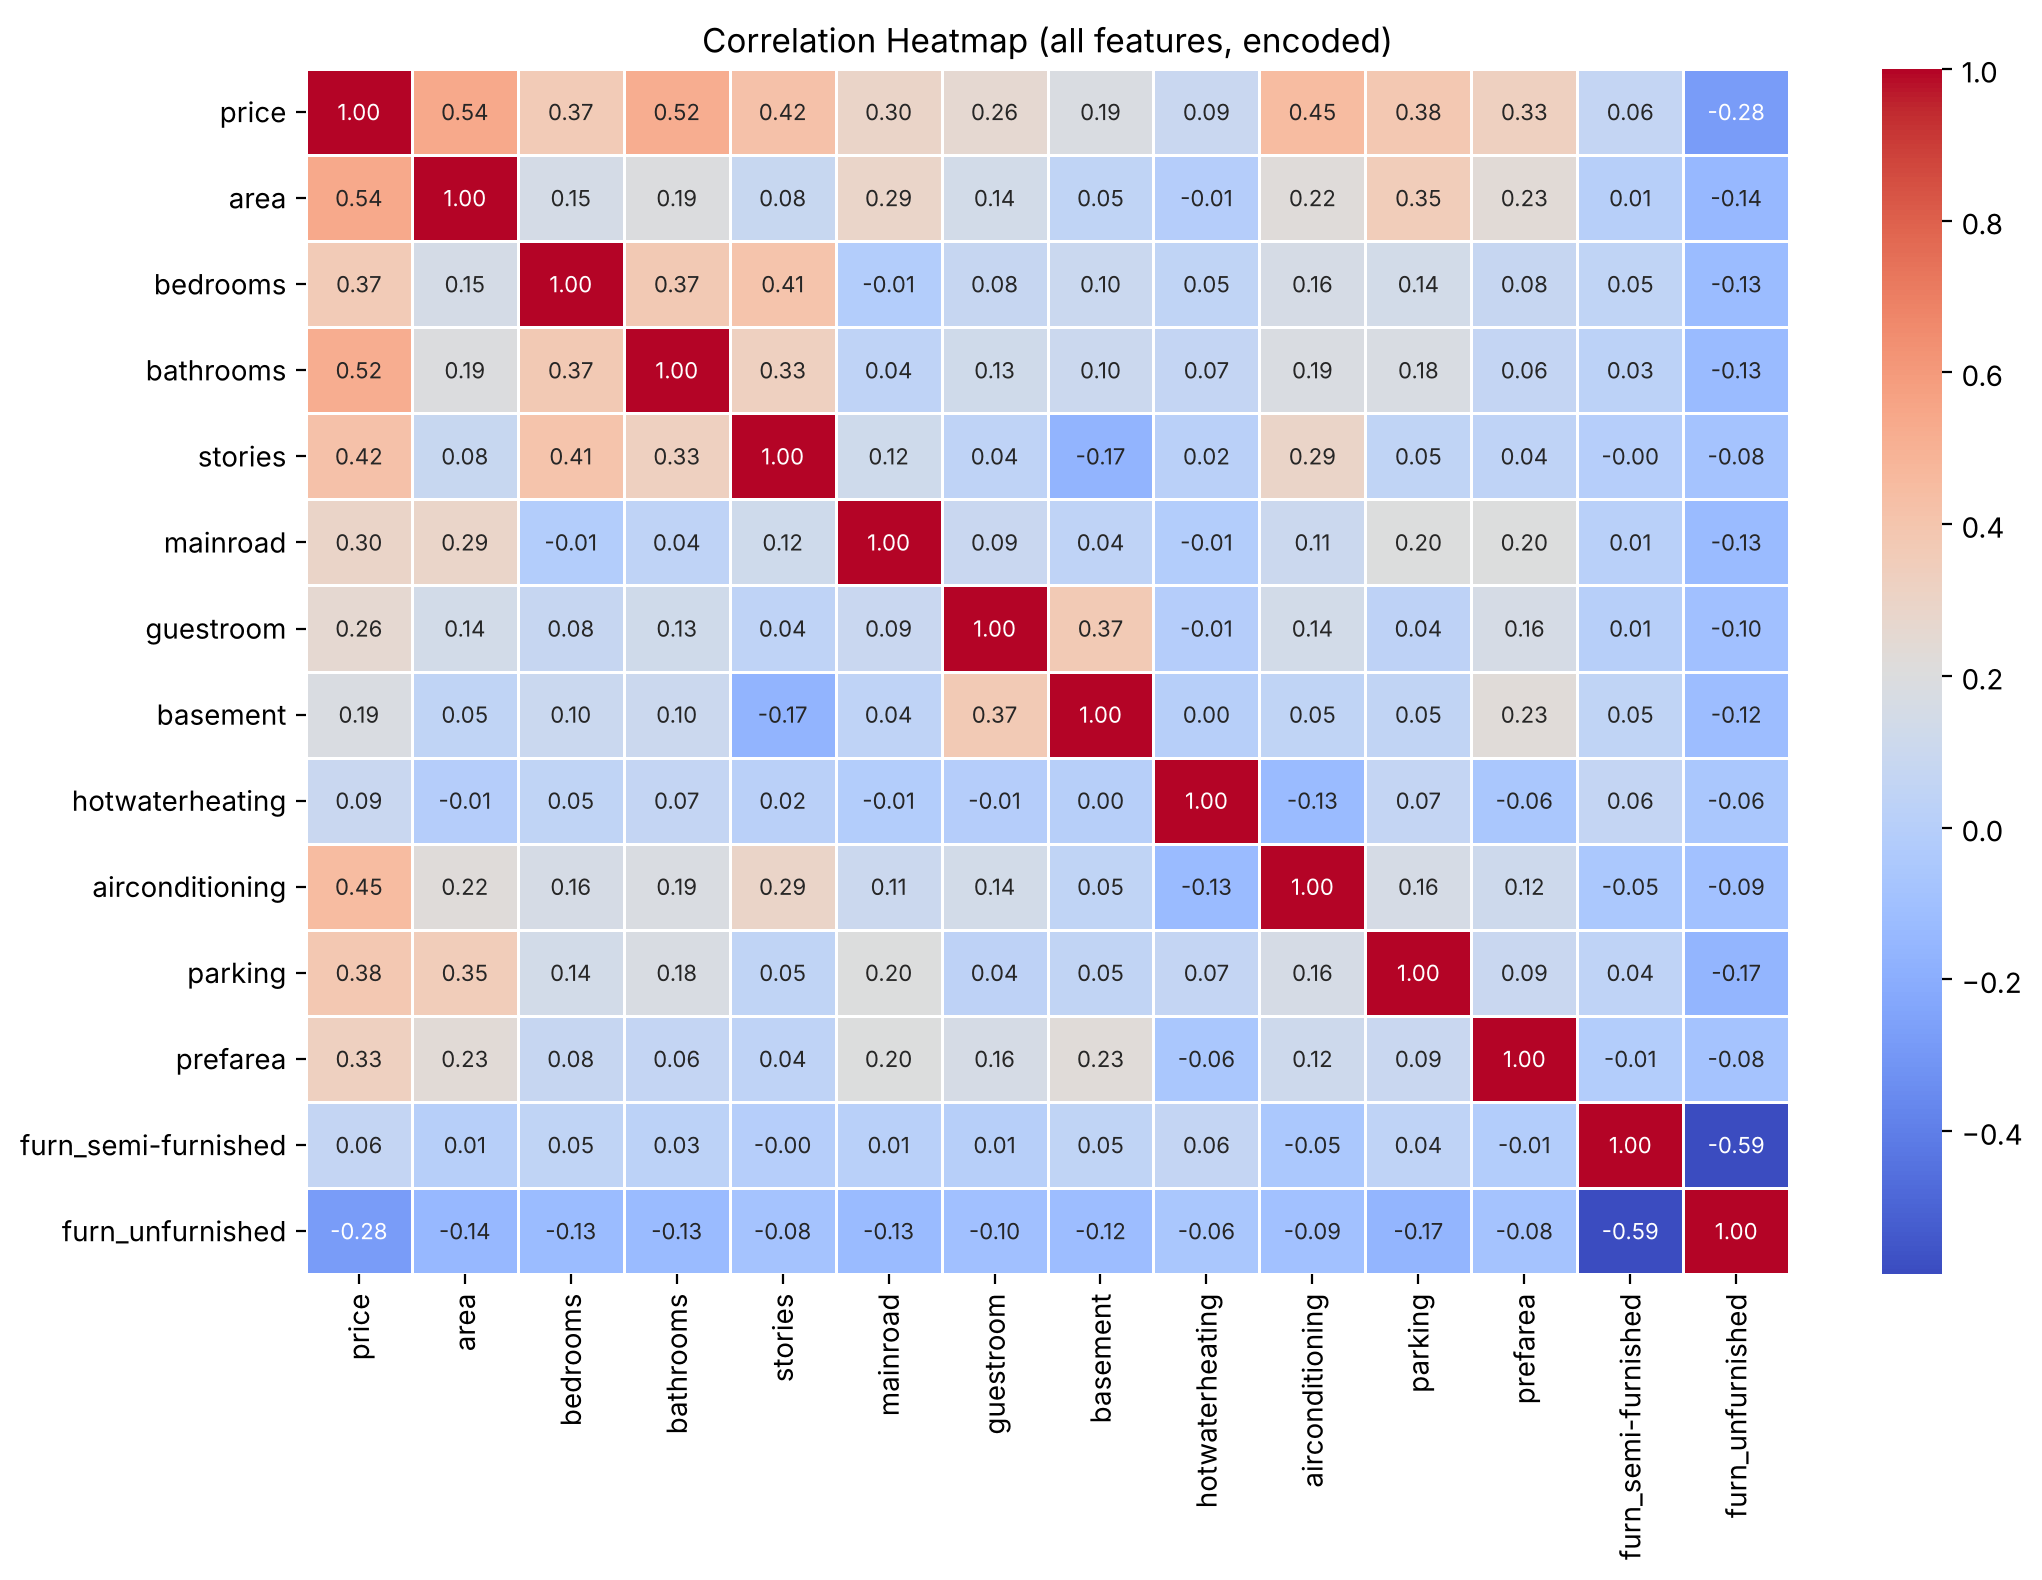

,Correlation with price
area,0.535997
bathrooms,0.517545
airconditioning,0.452954
stories,0.420712
parking,0.384394
bedrooms,0.366494
prefarea,0.329777
mainroad,0.296898
furn_unfurnished,-0.280587
guestroom,0.255517


In [6]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.4, annot_kws={"size": 8})
plt.title("Correlation Heatmap (all features, encoded)")
plt.tight_layout(); plt.show()

corr_with_price = df.corr()["price"].drop("price").sort_values(key=abs, ascending=False)
display(corr_with_price.to_frame("Correlation with price"))

**Observation:** The strongest links with price are area (r = 0.54), bathrooms (0.52), air conditioning (0.45), and stories (0.42). Correlation does not prove causation: a house with more bathrooms is often also a larger house. The highest correlation between two inputs is between the two furnishing dummies, which is expected because they are mutually exclusive. Among the real inputs, no pair stands out, and the VIF check in Section 11 confirms this.

## 6. Manual calculation (normal equations) on a small sample

Following Step 4 of the instructions, I take the first 8 houses and two features, **area (X1)** and **bedrooms (X2)**. I build the design matrix, compute XᵀX and Xᵀy, and solve for the coefficients. The sklearn check that follows confirms the result.

In [7]:
sample = df.loc[:7, ["area", "bedrooms", "price"]].reset_index(drop=True)
display(sample)

X_s = np.column_stack([np.ones(len(sample)), sample["area"], sample["bedrooms"]])
y_s = sample["price"].values.astype(float)

XtX = X_s.T @ X_s
Xty = X_s.T @ y_s
print("Design matrix X:\n", X_s)
print("\nXᵀX:\n", XtX)
print("\nXᵀy:\n", Xty)

b = np.linalg.solve(XtX, Xty)
print("\nSolved coefficients: b0 = %.2f, b1 (area) = %.4f, b2 (bedrooms) = %.2f" % tuple(b))

first_pred = X_s[0] @ b
print("First house: predicted = %.2f, actual = %.2f, residual = %.2f" % (first_pred, y_s[0], y_s[0] - first_pred))

,area,bedrooms,price
0,7420,4,13300000
1,8960,4,12250000
2,9960,3,12250000
3,7500,4,12215000
4,7420,4,11410000
5,7500,3,10850000
6,8580,4,10150000
7,16200,5,10150000


Design matrix X:
 [[1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 8.96e+03 4.00e+00]
 [1.00e+00 9.96e+03 3.00e+00]
 [1.00e+00 7.50e+03 4.00e+00]
 [1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 7.50e+03 3.00e+00]
 [1.00e+00 8.58e+03 4.00e+00]
 [1.00e+00 1.62e+04 5.00e+00]]

XᵀX:
 [[8.000000e+00 7.354000e+04 3.100000e+01]
 [7.354000e+04 7.381524e+08 2.929000e+05]
 [3.100000e+01 2.929000e+05 1.230000e+02]]

Xᵀy:
 [9.257500e+07 8.396227e+11 3.573500e+08]

Solved coefficients: b0 = 13147372.71, b1 (area) = -188.0925, b2 (bedrooms) = 39623.78
First house: predicted = 11910221.84, actual = 13300000.00, residual = 1389778.16


In [8]:
lib = LinearRegression().fit(sample[["area", "bedrooms"]], sample["price"])
print("sklearn intercept:", round(lib.intercept_, 2), "| coefficients:", lib.coef_.round(4))
print("Difference from manual b0, b1, b2:", np.round(np.r_[lib.intercept_, lib.coef_] - b, 6))

sklearn intercept: 13147372.71 | coefficients: [ -188.0925 39623.7803]
Difference from manual b0, b1, b2: [ 0. -0.  0.]


**Observation:** The manual and sklearn coefficients agree to numerical precision. The area coefficient is negative for these 8 houses, which is not what the full dataset shows (Section 9). With only 8 rows, a few unusual houses can flip the sign, so this result is a check on the mathematics, not a finding about the market.

## 7. Train / test split

I use an 80:20 split with a fixed random seed. The test set is used only for final evaluation, and the scaler is not needed because ordinary least squares does not require scaling.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 436 | Test rows: 109


## 8. Baseline and single-feature model

**Benchmarks:** (a) predict the training mean price for every house, and (b) a single-feature model using **area**, the feature most strongly correlated with price in the training data.

In [10]:
def evaluate(y_true, y_pred, n_features):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2,
        "Adjusted R2": 1 - (1 - r2) * (n - 1) / (n - n_features - 1),
    }

# (a) mean baseline
mean_pred = np.full(len(y_test), y_train.mean())
base_metrics = evaluate(y_test, mean_pred, 0)

# (b) single-feature model using the most correlated feature (from training data only)
train_corr = pd.concat([X_train, y_train], axis=1).corr()["price"].drop("price").abs()
best_feature = train_corr.idxmax()
single = LinearRegression().fit(X_train[[best_feature]], y_train)
single_pred = single.predict(X_test[[best_feature]])
single_metrics = evaluate(y_test, single_pred, 1)

print("Most correlated feature (training data):", best_feature)
print("Single-feature model: intercept = %.2f, coefficient = %.2f" % (single.intercept_, single.coef_[0]))

Most correlated feature (training data): area
Single-feature model: intercept = 2512254.26, coefficient = 425.73


## 9. Multiple linear regression

In [11]:
multi = LinearRegression().fit(X_train, y_train)
multi_pred = multi.predict(X_test)

coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient": multi.coef_}).round(2)
print("Intercept:", round(multi.intercept_, 2))
display(coef_table)

Intercept: 260032.36


,Feature,Coefficient
0,area,235.97
1,bedrooms,76778.70
2,bathrooms,1094444.79
3,stories,407476.59
4,mainroad,367919.95
5,guestroom,231610.04
6,basement,390251.18
7,hotwaterheating,684649.89
8,airconditioning,791426.74
9,parking,224841.91


**Interpretation (units are price units, holding the other features constant):**
- **Area:** each extra square foot adds about 236 to the price.
- **Bathrooms:** each extra bathroom adds about 1.09 million, the largest single effect in the model.
- **Air conditioning:** adds about 791 thousand.
- **Hot water heating:** adds about 685 thousand. This is a large effect for a feature found in few houses, so it is one to check before trusting (see Section 12).
- **Furnishing:** relative to furnished houses, semi-furnished houses are about 127 thousand cheaper and unfurnished houses about 414 thousand cheaper.
- **Intercept:** about 260 thousand. This is not meaningful, since a house with zero area and no rooms does not exist.

Raw coefficients depend on units, so the table below uses standardised coefficients to compare how strongly each feature moves price. This shows association, not causation.

In [12]:
std_coef = pd.Series(multi.coef_ * X_train.std().values / y_train.std(), index=X.columns)
display(std_coef.sort_values(key=abs, ascending=False).round(3).to_frame("Standardised coefficient"))

,Standardised coefficient
bathrooms,0.297
area,0.296
airconditioning,0.208
stories,0.199
prefarea,0.152
furn_unfurnished,-0.109
parking,0.109
basement,0.107
hotwaterheating,0.085
mainroad,0.073


**Observation:** Bathrooms (0.30) and area (0.30) have the largest standardised effects, followed by air conditioning (0.21) and stories (0.20). Bedrooms has almost no effect once area and bathrooms are known (0.03), which suggests bedroom count mostly tells the same story as house size.

## 10. Model comparison on the test set

In [13]:
results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²", "Adjusted R²"],
    "Mean baseline": list(base_metrics.values()),
    "Single feature (area)": list(single_metrics.values()),
    "Multiple regression": list(evaluate(y_test, multi_pred, X.shape[1]).values()),
}).set_index("Metric")
display(results.round(3))

train_r2 = r2_score(y_train, multi.predict(X_train))
print("Multiple regression: training R² = %.3f, test R² = %.3f" % (train_r2, results.loc["R²", "Multiple regression"]))

,Mean baseline,Single feature (area),Multiple regression
Metric,,,
MAE,1.748625e+06,1.474748e+06,9.700434e+05
MSE,5.145177e+12,3.675287e+12,1.754319e+12
RMSE,2.268298e+06,1.917104e+06,1.324507e+06
R²,-1.800000e-02,2.730000e-01,6.530000e-01
Adjusted R²,-1.800000e-02,2.660000e-01,6.050000e-01


Multiple regression: training R² = 0.686, test R² = 0.653


**Interpretation:**
- **Mean baseline:** the test R² is slightly negative, so predicting the average price does no better than guessing.
- **Single feature (area):** explains about 27% of the variation in test prices. The average error (MAE) is about 1.47 million.
- **Multiple regression:** explains about 65% of test-set variation and cuts the average error to about 0.97 million, a meaningful improvement over the single-feature model.
- **Overfitting check:** training R² (0.69) is close to test R² (0.65), so the model is not memorising the training data.
- **Adjusted R²** (0.61) is only a little below R², which means the 12 features are contributing real information rather than noise.

The extra features justify their complexity. The gain is large (the test R² more than doubles), and the training and test scores are close.

## 11. Multicollinearity check (VIF)

In [14]:
X_const = sm.add_constant(X)
vif = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]
}).sort_values("VIF", ascending=False)
display(vif.round(2))

,Feature,VIF
12,furn_unfurnished,1.67
11,furn_semi-furnished,1.58
3,stories,1.48
1,bedrooms,1.37
0,area,1.33
6,basement,1.32
2,bathrooms,1.29
5,guestroom,1.21
9,parking,1.21
8,airconditioning,1.21


**Observation:** Every VIF is below 2, far under the common threshold of 5. Multicollinearity is therefore not a problem for this model. The two furnishing dummies are the highest, which is expected because they are mutually exclusive categories. No features need to be dropped or combined.

## 12. Residual analysis and assumptions

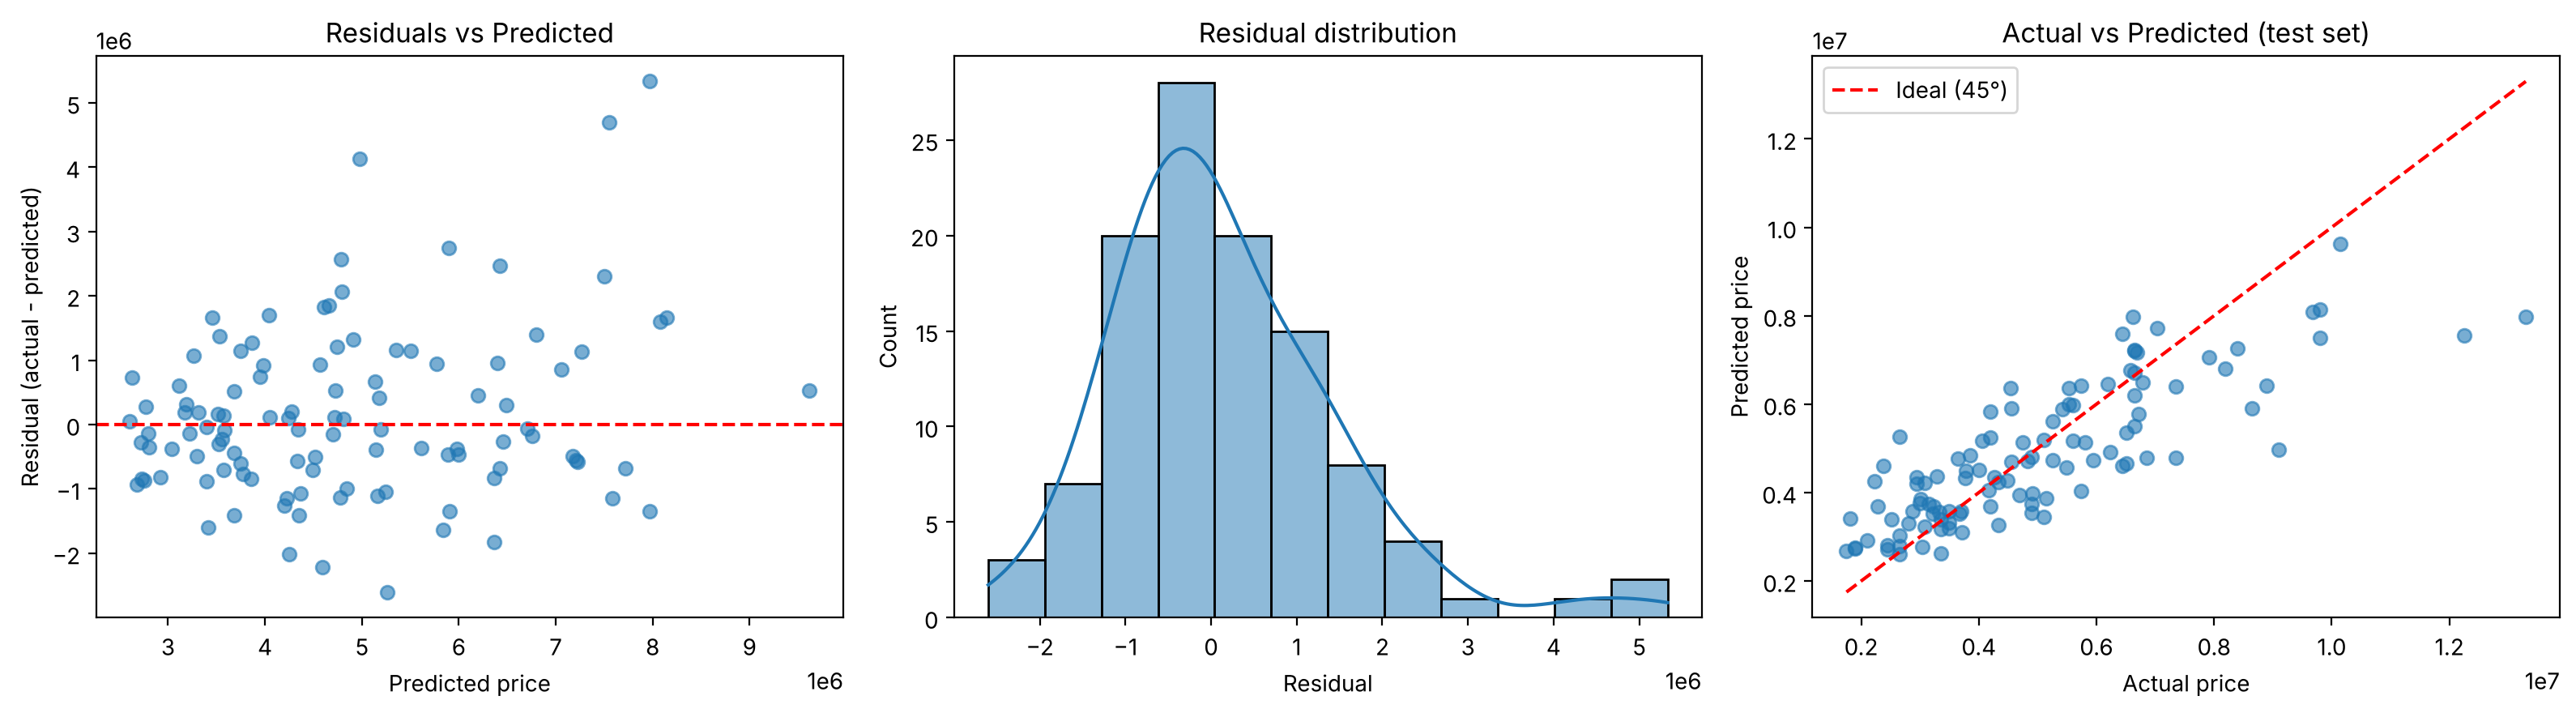

Residual mean: 146055 | std: 1316429 | skew: 1.18
Share of test houses predicted within 20% of actual price: 59.6%


In [15]:
residuals = y_test.values - multi_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(multi_pred, residuals, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(title="Residuals vs Predicted", xlabel="Predicted price", ylabel="Residual (actual - predicted)")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set(title="Residual distribution", xlabel="Residual", ylabel="Count")

axes[2].scatter(y_test, multi_pred, alpha=0.6)
lims = [min(y_test.min(), multi_pred.min()), max(y_test.max(), multi_pred.max())]
axes[2].plot(lims, lims, "r--", label="Ideal (45°)")
axes[2].set(title="Actual vs Predicted (test set)", xlabel="Actual price", ylabel="Predicted price")
axes[2].legend()
plt.tight_layout(); plt.show()

print("Residual mean: %.0f | std: %.0f | skew: %.2f" % (residuals.mean(), residuals.std(), pd.Series(residuals).skew()))
print("Share of test houses predicted within 20%% of actual price: %.1f%%" % (100 * np.mean(np.abs(residuals / y_test.values) <= 0.2)))

**Residual observations:**
- **Residuals vs predicted:** the spread widens as predicted price rises, so error variance is not constant (heteroscedasticity). The average absolute error is about 616 thousand in the lowest third of predictions, about 1.04 million in the middle third, and about 1.27 million in the highest third. The model is least reliable for expensive houses.
- **Residual histogram:** residuals are right-skewed (skew about 1.2). A few very expensive houses are under-predicted by large amounts, so the errors are not symmetric.
- **Actual vs predicted:** most points sit near the 45° line for mid-priced houses, but the most expensive houses fall below it, so the model tends to underestimate the top of the market.

**Assumptions:**
- *Linearity:* reasonable for most features, but the price–area relationship curves upward at the top end.
- *Independence of errors:* reasonable, since each row is a separate listing. This is an assumption, not something I could test.
- *Constant error variance:* **doubtful**, as the residual plot shows.
- *Approximately normal errors:* **doubtful**, because of the right skew.
- *No severe multicollinearity:* **reasonable**, confirmed by VIF.

**Remedy I would try next:** log-transform the price (and possibly area), which often fixes skew and unequal spread, then compare test metrics against this model.

## 13. New prediction

In [16]:
new_house = X.median().to_frame().T
new_house.loc[0, ["area", "bedrooms", "bathrooms", "stories", "parking"]] = [6000, 3, 2, 2, 1]
new_house.loc[0, "mainroad"] = 1
print("New house (features):")
display(new_house.T.rename(columns={0: "value"}))

new_pred = multi.predict(new_house)[0]
print("Predicted price: %.0f" % new_pred)
print("Training area range: %d to %d sq ft (the new house is inside this range)" % (X.area.min(), X.area.max()))

New house (features):


,value
area,6000.0
bedrooms,3.0
bathrooms,2.0
stories,2.0
mainroad,1.0
guestroom,0.0
basement,0.0
hotwaterheating,0.0
airconditioning,0.0
parking,1.0


Predicted price: 5502786
Training area range: 1650 to 16200 sq ft (the new house is inside this range)


## 14. Conclusion, limitations, and ethics

**Summary:** Using 12 features on 545 houses, the multiple regression explains about 65% of test-set price variation and has an average error of about 0.97 million. A single feature (area) explains about 27%, and the mean baseline explains nothing. Bathrooms, area, and air conditioning are the strongest drivers.

**Limitations:**
- The model is linear, so it misses the curved price–area relationship at the top of the market.
- Errors are larger for expensive houses, so predictions there should be treated as rough.
- The dataset is small (545 rows) and has no location information, which is probably the largest missing driver of price.
- The currency and collection date of the source are not stated, so absolute values should not be compared with current market prices.
- The hot-water heating coefficient is large for a feature present in few houses. I would check its sample size before relying on it.
- Coefficients show association in this sample, not causation.

**What the model should NOT be used for:** setting an official valuation, approving mortgages, or judging a specific house without an appraisal. A prediction is an estimate, not a guarantee.

**Ethics:** The data describes houses, not people, so there is no personal data concern. A biased estimate could still mislead buyers or sellers, so predictions should be shown with their error range.

## Decision log
| Decision | Alternatives considered | Reason |
|---|---|---|
| Kept all 545 rows | Remove high-price outliers | The high prices are plausible and removing them would hide real market segments. |
| Kept all 12 features | Drop bedrooms (small standardised effect, 0.03) | Bedrooms shows no sign of harm and VIF is low. Dropping it was not tested, so this is not a claim that it helps. |
| Furnished as reference category | Drop another category | Gives the most interpretable comparison (furnished vs semi and unfurnished). |
| Test set used once for final metrics | Tune on the test set | Keeps the reported test metrics honest. |
| Baseline = training mean | No baseline | A model is only useful if it beats a simple benchmark. |
| Did not use a log transform in the main model | Log-transform price | Kept the model in original units for interpretability; proposed as the next step. |